In [5]:
# Mount google drive

# from google.colab import drive
# drive.mount("/content/drive")

In [5]:
#pip install requests_cache

In [ ]:
# pip install optuna

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import datetime
import time, os

#=============Libraries for feature extraction=============

from tqdm import tqdm
import optuna
#import whois
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, precision_score, f1_score, recall_score, confusion_matrix,roc_auc_score
import xgboost as xgb

In [2]:
# Helper functions to display confusion matrix and perform cross-validation

def plot_confusion_matrix(y_true, y_pred, class_names, figsize=(8, 6)):

    #Visualize the confusion matrix for model evaluation.

    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=figsize)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title("Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.show()


def stratified_kfold_cv(model, X, y, n_splits=None, verbose=False):

    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=65)
    f1_scores = []

    for fold, (train_index, test_index) in enumerate(skf.split(X, y)):
        if verbose:
            print(f"Fold {fold+1}/{n_splits}")

        # Split the data into training and testing sets
        X_train, X_test = X.iloc[train_index], X.iloc[test_index]
        y_train, y_test = y.iloc[train_index], y.iloc[test_index]


        model.fit(X_train, y_train)
        # Make predictions and evaluate F1 score
        preds = model.predict(X_test)
        f1 = f1_score(y_test, preds)
        f1_scores.append(f1)

        if verbose:
            print(f"F1 Score: {f1:.4f}")

    mean_f1_score = np.mean(f1_scores)
    if verbose:
        print(f"Mean F1 Score: {mean_f1_score:.4f}")

    return mean_f1_score

In [3]:
# Read the data
raw_data = pd.read_csv("dataset_phishing.csv")
raw_data.head()

,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
0,http://www.crestonwood.com/router.php,37,19,0,3,0,0,0,0,0,...,0,1,0,45,-1,0,1,1,4,legitimate
1,http://shadetreetechnology.com/V4/validation/a...,77,23,1,1,0,0,0,0,0,...,1,0,0,77,5767,0,0,1,2,phishing
2,https://support-appleld.com.secureupdate.duila...,126,50,1,4,1,0,1,2,0,...,1,0,0,14,4004,5828815,0,1,0,phishing
3,http://rgipt.ac.in,18,11,0,2,0,0,0,0,0,...,1,0,0,62,-1,107721,0,0,3,legitimate
4,http://www.iracing.com/tracks/gateway-motorspo...,55,15,0,2,2,0,0,0,0,...,0,1,0,224,8175,8725,0,0,6,legitimate


In [4]:
raw_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11430 entries, 0 to 11429
Data columns (total 89 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   url                         11430 non-null  object 
 1   length_url                  11430 non-null  int64  
 2   length_hostname             11430 non-null  int64  
 3   ip                          11430 non-null  int64  
 4   nb_dots                     11430 non-null  int64  
 5   nb_hyphens                  11430 non-null  int64  
 6   nb_at                       11430 non-null  int64  
 7   nb_qm                       11430 non-null  int64  
 8   nb_and                      11430 non-null  int64  
 9   nb_or                       11430 non-null  int64  
 10  nb_eq                       11430 non-null  int64  
 11  nb_underscore               11430 non-null  int64  
 12  nb_tilde                    11430 non-null  int64  
 13  nb_percent                  114

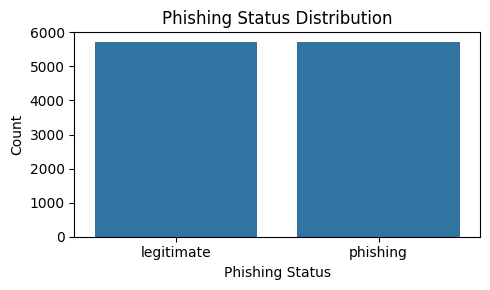

In [5]:
# Visualize target distribution
plt.figure(figsize=(5,3))

sns.countplot(data=raw_data, x="status")
plt.title('Phishing Status Distribution')
plt.xlabel('Phishing Status')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

In [6]:
#print duplicate rows

raw_data[raw_data['url'].duplicated()]

,url,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,...,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,web_traffic,dns_record,google_index,page_rank,status
11305,http://e710z0ear.du.r.appspot.com/c:/users/use...,54,26,0,4,0,0,0,0,0,...,1,1,0,230,5614,0,0,1,5,phishing


In [7]:
# Remove duplicated row (second entry)

raw_data.drop_duplicates(subset='url', keep='first', inplace=True)

In [8]:
#dataset after removing duplicates

raw_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 11429 entries, 0 to 11429
Data columns (total 89 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   url                         11429 non-null  object 
 1   length_url                  11429 non-null  int64  
 2   length_hostname             11429 non-null  int64  
 3   ip                          11429 non-null  int64  
 4   nb_dots                     11429 non-null  int64  
 5   nb_hyphens                  11429 non-null  int64  
 6   nb_at                       11429 non-null  int64  
 7   nb_qm                       11429 non-null  int64  
 8   nb_and                      11429 non-null  int64  
 9   nb_or                       11429 non-null  int64  
 10  nb_eq                       11429 non-null  int64  
 11  nb_underscore               11429 non-null  int64  
 12  nb_tilde                    11429 non-null  int64  
 13  nb_percent                  11429 no

## Feature Extraction

In this step here, features to be extracted include:

*   Lexical features
*   Content-based features

# **Lexical Features**

> Lexical features are features that are derived from the url address itself.

Examples of features to be extracted:
- Length of url (url_len)
- Length of hostname (hostname_len)
- Number of dots in the hostname part of the url (num_dots)
> Typically, legitimate urls have just 2-3 dots in the hostname part of the url
- Number of digits in url (len_num_url)
- Repeated number of digits in url (rpt_num_url)
- Presence of IP address in domain (ip address)
- Presence of @ in url (url@)
- Depth of url which means the number of subpages in the url (url_depth)
- Redirection in the url symbol (url_//): For most legitimate website, the // comes after http: or https:
- Presence of http or https in domain name
- Use of url shortening service
- Number of hyphens in domain
- Presence of hyphens
- Existence of sensitive word in url
- Existence of trendy brand name
- Existence of uppercase letters in url
- Number of question marks in url
- Number of equals sign
- Number of slashes
- Number of equals sign
- Number of times 'www' appeared in the url
- Ratio of numeric characters to total url length
- Ratio of numeric characters in the hostname part.
- tld_in_subdomain
> 1 if a top-level domain (like .com, .net) appears within the subdomain
- Length of the shortest word when the hostname is split by dots or hyphens.
- Length of the longest word in the entire URL string.
-Length of the longest word found in the path part

# **Content-Based Features**
- Total number of hyperlinks on the page.
- Ratio of internal links (same domain) to total hyperlinks
- External hyperlink ratio
- Presence of HTML title tag
> 1 if the HTML title tag is missing or empty.
- Presence of domain name in  page title
> 1 if the page title contains the domain name.
- 1, if external link or php file or “ ”, “#”,
“javascript:void(0)” in action field
- common page detection ratio

# **Host-Based Features**

- Google index - 1 if the sites appears on google index
- Page rank
- Domain age
- Domain registration length
- Web traffic
- DNS record



In [9]:
# === Insert this in a NEW code cell (between 14 and 15) ===

print("Starting to create v2 DataFrame...")

# List of columns to drop: the 31 "impossible" features + the original 'url'
columns_to_drop = [
    # The 'url' string itself
    'url',
    
    # The "Impossible 3" (require paid/banned APIs or are deprecated)
    'web_traffic', 
    'google_index', 
    'page_rank',
    
    # Requires complex 3rd-party lists (brands, keywords) or are 3rd-party services
    'phish_hints', 
    'domain_in_brand', 
    'brand_in_subdomain', 
    'brand_in_path',
    'suspecious_tld', 
    'statistical_report',
    
    # Too complex/slow to parse from HTML content in real-time
    'nb_extCSS', 
    'ratio_intRedirection', 
    'ratio_extRedirection', 
    'ratio_intErrors', 
    'ratio_extErrors',
    'ratio_intMedia', 
    'ratio_extMedia',
    'sfh', # Server Form Handler
    'safe_anchor',
    
    # Requires complex redirection following
    'nb_external_redirection', 
    
    # Complex text processing (easier to re-train without)
    'length_words_raw', 
    'char_repeat', 
    'shortest_words_raw', 
    'shortest_word_host', 
    'shortest_word_path', 
    'longest_words_raw', 
    'longest_word_host', 
    'longest_word_path', 
    'avg_words_raw', 
    'avg_word_host', 
    'avg_word_path'
]

# Check which of these columns actually exist in the DataFrame to avoid errors
cols_to_drop_existing = [col for col in columns_to_drop if col in raw_data.columns]

print(f"Original columns: {raw_data.shape[1]}")
print(f"Columns to drop: {len(cols_to_drop_existing)}")

# Create the new DataFrame 'df_v2' from the original 'raw_data'
df_v2 = raw_data.drop(columns=cols_to_drop_existing)

# Your new DataFrame should have 89 - 32 = 57 columns (56 features + 1 target)
print(f"New 'df_v2' columns: {df_v2.shape[1]}")

Starting to create v2 DataFrame...
Original columns: 89
Columns to drop: 31
New 'df_v2' columns: 58


In [10]:
# === This is your NEW Cell 15 ===

# map categories in the status column: legitimate=0 and phishing=1
# We are now using our new 'df_v2' DataFrame
df_v2['status'] = df_v2['status'].map({'legitimate':0, 'phishing':1})

print("Mapped 'status' column to 0 and 1.")
df_v2.head()

Mapped 'status' column to 0 and 1.


,length_url,length_hostname,ip,nb_dots,nb_hyphens,nb_at,nb_qm,nb_and,nb_or,nb_eq,...,onmouseover,right_clic,empty_title,domain_in_title,domain_with_copyright,whois_registered_domain,domain_registration_length,domain_age,dns_record,status
0,37,19,0,3,0,0,0,0,0,0,...,0,0,0,0,1,0,45,-1,1,0
1,77,23,1,1,0,0,0,0,0,0,...,0,0,0,1,0,0,77,5767,0,1
2,126,50,1,4,1,0,1,2,0,3,...,0,0,0,1,0,0,14,4004,0,1
3,18,11,0,2,0,0,0,0,0,0,...,0,0,0,1,0,0,62,-1,0,0
4,55,15,0,2,2,0,0,0,0,0,...,0,0,0,0,1,0,224,8175,0,0


In [11]:
# === This is your NEW Cell 16 ===

# Separate target variable from features, using our new df_v2
target = df_v2['status']
features = df_v2.drop(['status'], axis=1)

print('New Features Shape (v2):', features.shape) # Should be (11429, 56)
print('New Target Shape (v2):', target.shape)

# You can also print the features to be 100% sure
print("\n--- Final 57 features for v2 model ---")
print(features.columns.tolist())

New Features Shape (v2): (11429, 57)
New Target Shape (v2): (11429,)

--- Final 57 features for v2 model ---
['length_url', 'length_hostname', 'ip', 'nb_dots', 'nb_hyphens', 'nb_at', 'nb_qm', 'nb_and', 'nb_or', 'nb_eq', 'nb_underscore', 'nb_tilde', 'nb_percent', 'nb_slash', 'nb_star', 'nb_colon', 'nb_comma', 'nb_semicolumn', 'nb_dollar', 'nb_space', 'nb_www', 'nb_com', 'nb_dslash', 'http_in_path', 'https_token', 'ratio_digits_url', 'ratio_digits_host', 'punycode', 'port', 'tld_in_path', 'tld_in_subdomain', 'abnormal_subdomain', 'nb_subdomains', 'prefix_suffix', 'random_domain', 'shortening_service', 'path_extension', 'nb_redirection', 'nb_hyperlinks', 'ratio_intHyperlinks', 'ratio_extHyperlinks', 'ratio_nullHyperlinks', 'login_form', 'external_favicon', 'links_in_tags', 'submit_email', 'iframe', 'popup_window', 'onmouseover', 'right_clic', 'empty_title', 'domain_in_title', 'domain_with_copyright', 'whois_registered_domain', 'domain_registration_length', 'domain_age', 'dns_record']


In [12]:
# Split data into train and test
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size=0.2, random_state=11)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((9143, 57), (2286, 57), (9143,), (2286,))

In [13]:
import joblib

# This saves the X_train DataFrame as a joblib file.
# This format perfectly saves all data types (floats, ints)
# and solves our string conversion error.
joblib.dump(X_train, 'X_train_v2.joblib')

print("--- 'X_train_v2.joblib' (the clean data) has been saved! ---")

--- 'X_train_v2.joblib' (the clean data) has been saved! ---


In [13]:
#Target names
target_names = ['Legitimate-0', 'Phishing-1']

In [14]:
#create a baseline model with decision tree

from sklearn.tree import DecisionTreeClassifier

clf = DecisionTreeClassifier(
    criterion='gini',
    max_depth=20,
    random_state=23
)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.9059492563429571

Classification Report:
               precision    recall  f1-score   support

           0       0.91      0.90      0.90      1118
           1       0.90      0.91      0.91      1168

    accuracy                           0.91      2286
   macro avg       0.91      0.91      0.91      2286
weighted avg       0.91      0.91      0.91      2286



In [15]:
# Build baseline model for randomForest and Xgboost

base_rf = RandomForestClassifier(n_estimators=150, random_state=23)
base_rf.fit(X_train, y_train)
y_pred_rf = base_rf.predict(X_test)

base_xgb = xgb.XGBClassifier(n_estimators=150, random_state=23)
base_xgb.fit(X_train, y_train)
y_pred_xgb = base_xgb.predict(X_test)

print("BaseRF Accuracy:", accuracy_score(y_test, y_pred_rf), end='\n\n')
print("BaseXGB Accuracy:", accuracy_score(y_test, y_pred_xgb))

BaseRF Accuracy: 0.9391951006124234

BaseXGB Accuracy: 0.9453193350831146


HyperParameter Tuning

In [16]:
def tune_model_with_optuna(model_name, X_train, y_train, n_trials=50, n_splits=5):


    # Define the objective function
    def objective(trial):
        # Define model-specific parameter search spaces
        if model_name.lower() == "xgboost":
            params = {
                "n_estimators": trial.suggest_int("n_estimators", 100, 1000),
                "max_depth": trial.suggest_int("max_depth", 3, 15),
                "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.2, log=True),
                "alpha": trial.suggest_float("alpha", 0, 10.0),
                "subsample": trial.suggest_float("subsample", 0.5, 1.0),
                "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
                "gamma": trial.suggest_float("gamma", 0, 5.0),
                "random_state": trial.suggest_int("random_state",0,100),
                "eval_metric": "logloss"
            }
            model = xgb.XGBClassifier(**params)

        elif model_name.lower() == "randomforest":
            params = {
                "n_estimators": trial.suggest_int("n_estimators", 100, 500),
                "max_depth": trial.suggest_int("max_depth", 5, 25),
                "min_samples_split": trial.suggest_int("min_samples_split", 2, 10),
                "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 5),
                "max_features": trial.suggest_categorical("max_features", ["sqrt", "log2"]),
                "random_state": trial.suggest_int("random_state",0,100),
                "n_jobs": -1
            }
            model = RandomForestClassifier(**params)

        else:
            raise ValueError("Only 'xgboost' or 'randomforest' are supported.")

        # Stratified K-Fold cross-validation
        skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
        f1_scores = []

        for train_idx, val_idx in skf.split(X_train, y_train):
            X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
            y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

            model.fit(X_tr, y_tr)
            preds = model.predict(X_val)
            f1_scores.append(f1_score(y_val, preds))

        return np.mean(f1_scores)

    # Create and run Optuna study
    study = optuna.create_study(direction="maximize")

    # progress bar
    with tqdm(total=n_trials, desc=f"Tuning {model_name}", ncols=80) as pbar:
        def callback(study, trial):
            pbar.update(1)
        study.optimize(objective, n_trials=n_trials, callbacks=[callback])

    print(f"\n Best parameters for {model_name}:")
    print(study.best_params)
    print(f" Best mean F1 score: {study.best_value:.4f}")

    return study


In [ ]:
#Random Forest
study_rf = tune_model_with_optuna("randomforest", X_train, y_train, n_trials=50)

[I 2025-10-31 16:21:28,351] A new study created in memory with name: no-name-5dca71d4-a8b6-4f11-9750-8910c3debe2e
Tuning randomforest: 100%|██████████████████████| 50/50 [20:12<00:00, 24.25s/it]


 Best parameters for randomforest:
{'n_estimators': 460, 'max_depth': 25, 'min_samples_split': 3, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'random_state': 40}
 Best mean F1 score: 0.9414


In [18]:
# For XGBoost
study_xgb = tune_model_with_optuna("xgboost", X_train, y_train, n_trials=50)

[I 2025-10-31 16:41:40,830] A new study created in memory with name: no-name-1558b1f8-613c-403f-8de3-0ff067ddd2ec
Tuning xgboost: 100%|███████████████████████████| 50/50 [17:28<00:00, 20.96s/it]


 Best parameters for xgboost:
{'n_estimators': 777, 'max_depth': 13, 'learning_rate': 0.13111068042718263, 'alpha': 2.3040085093843508, 'subsample': 0.885274113362328, 'colsample_bytree': 0.9202787854179977, 'gamma': 0.351188688592578, 'random_state': 85}
 Best mean F1 score: 0.9460


In [19]:
# Carry out cross validation for RandomForest
rf_model = RandomForestClassifier(n_estimators=218, max_depth=19, min_samples_split=4,
                                  min_samples_leaf=1, max_features='sqrt', random_state=36)
mean_f1_rf = stratified_kfold_cv(rf_model,X_train, y_train, n_splits=5,verbose=True)

Fold 1/5
F1 Score: 0.9396
Fold 2/5
F1 Score: 0.9369
Fold 3/5
F1 Score: 0.9433
Fold 4/5
F1 Score: 0.9381
Fold 5/5
F1 Score: 0.9401
Mean F1 Score: 0.9396


In [20]:
# Carry out cross validation for Xgboost
xgboost_model = xgb.XGBClassifier(n_estimators=589, max_depth=7, learning_rate=0.14478146277890203,
 alpha=0.06198616387881664, subsample=0.8971567845646136, colsample_bytree=0.5538891096462765, gamma=0.014222221953652789, random_state=29)
mean_f1_xgboost = stratified_kfold_cv(xgboost_model, X_train, y_train, n_splits=5,verbose=True)
# Print the mean F1-score across folds
print(f"Mean F1-Score across folds (XgBoost): {mean_f1_xgboost:.4f}")

Fold 1/5
F1 Score: 0.9474
Fold 2/5
F1 Score: 0.9449
Fold 3/5
F1 Score: 0.9538
Fold 4/5
F1 Score: 0.9555
Fold 5/5
F1 Score: 0.9507
Mean F1 Score: 0.9505
Mean F1-Score across folds (XgBoost): 0.9505


# Train Full training dataset

In [21]:
# Train with full training dataset

#Random Forest

rf_model.fit(X_train,y_train)
rf_pred = rf_model.predict(X_test)
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.93      0.95      0.94      1118
           1       0.95      0.93      0.94      1168

    accuracy                           0.94      2286
   macro avg       0.94      0.94      0.94      2286
weighted avg       0.94      0.94      0.94      2286



In [22]:
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
rf_auc = roc_auc_score(y_test, rf_pred)

print(f" Accuracy Score:  {rf_accuracy:.4f}")
print(f" Precision Score: {rf_precision:.4f}")
print(f" Recall Score:    {rf_recall:.4f}")
print(f" F1 Score:        {rf_f1:.4f}")
print(f" AUC Score:       {rf_auc:.4f}")

 Accuracy Score:  0.9392
 Precision Score: 0.9470
 Recall Score:    0.9332
 F1 Score:        0.9401
 AUC Score:       0.9393


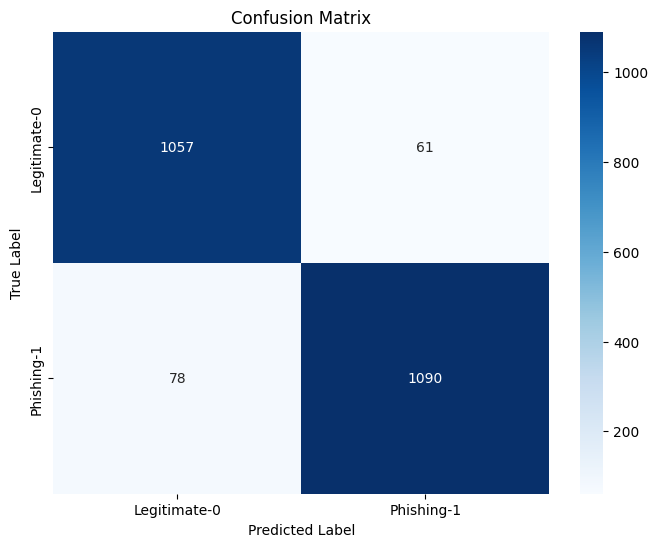

In [23]:
plot_confusion_matrix(y_test, rf_pred, target_names)

In [24]:
# Train with full training dataset

#Random Forest

xgboost_model.fit(X_train,y_train)
xgb_pred = xgboost_model.predict(X_test)
print(classification_report(y_test, xgb_pred))

              precision    recall  f1-score   support

           0       0.95      0.95      0.95      1118
           1       0.95      0.95      0.95      1168

    accuracy                           0.95      2286
   macro avg       0.95      0.95      0.95      2286
weighted avg       0.95      0.95      0.95      2286



In [25]:
xgb_accuracy = accuracy_score(y_test, xgb_pred)
xgb_precision = precision_score(y_test, xgb_pred)
xgb_recall = recall_score(y_test, xgb_pred)
xgb_f1 = f1_score(y_test, xgb_pred)
xgb_auc = roc_auc_score(y_test, xgb_pred)

print(f" Accuracy Score:  {xgb_accuracy:.4f}")
print(f" Precision Score: {xgb_precision:.4f}")
print(f" Recall Score:    {xgb_recall:.4f}")
print(f" F1 Score:        {xgb_f1:.4f}")
print(f" AUC Score:       {xgb_auc:.4f}")

 Accuracy Score:  0.9479
 Precision Score: 0.9494
 Recall Score:    0.9486
 F1 Score:        0.9490
 AUC Score:       0.9479


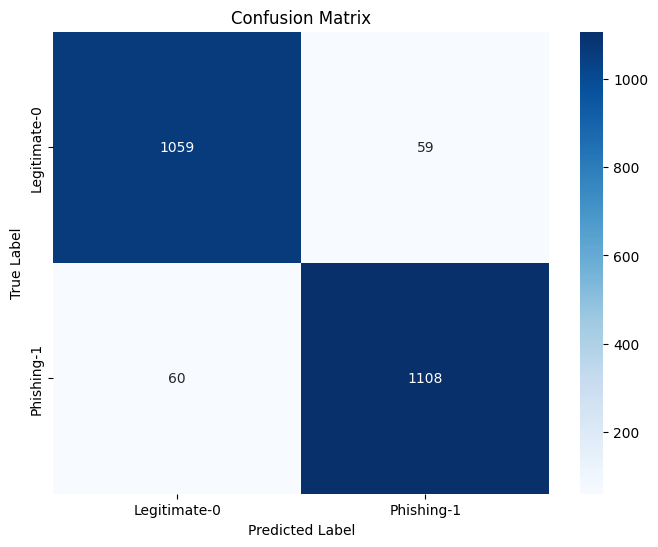

In [26]:
plot_confusion_matrix(y_test, xgb_pred, target_names)

In [27]:
# === This is your NEW Cell 32 ===
from joblib import dump

# Save the v2 model!
dump(xgboost_model, 'xgboost_model_v2.joblib')

['xgboost_model_v2.joblib']